# CVPR Assignment — COVID vs Non-COVID Chest X-Ray Classification with a CNN from Scratch

**Course:** 01203 Computer Vision and Pattern Recognition (Fall 26-27)
**Name:** Alvy Abedin Mumu   **ID:** 23-51446-1

**Dataset:** Resized (224x224) COVID and Non-COVID X-Ray Images, Mendeley Data (DOI: 10.17632/db4wdy7cdf.1). 12,594 images, 2 classes, about 192 MB.


We train the CNN **twice**:
- **Round 1:** basic transform only (no augmentation)
- **Round 2:** data augmentation + dropout

## 1. Setup

In [1]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np
import os, urllib.request, zipfile

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

torch.manual_seed(0)
np.random.seed(0)

Using device: cuda


## 2. Get the data


In [2]:
# STEP A: unzip the dataset (safe to run more than once)
import os, glob, subprocess

zips = glob.glob("/content/*.zip")
print("Zip files found:", zips)
assert len(zips) > 0, "Zip not found. Upload the dataset zip to the Files panel (left side), wait for the upload to finish, then run this cell again."

if not os.path.exists("/content/data"):
    subprocess.run(["unzip", "-q", zips[0], "-d", "/content/data"], check=True)
    print("Unzipped to /content/data")
else:
    print("/content/data already exists, skipping unzip")

Zip files found: ['/content/Resized (224x224) COVID and Non-COVID X-Ray Images.zip']
/content/data already exists, skipping unzip


In [3]:
# STEP B: find the dataset folders
# Dataset: "Resized (224x224) COVID and Non-COVID X-Ray Images" (Mendeley Data)


data_dir = "/content/data"

def find_base(root):
    """Return the folder that directly contains 'Train-Mendeley' and 'Val_Test_Kaggle'."""
    for current, subdirs, _ in os.walk(root):
        if "Train-Mendeley" in subdirs and "Val_Test_Kaggle" in subdirs:
            return current
    return None

base = find_base(data_dir)
assert base is not None, "Dataset folder not found. Check that the zip was unzipped to /content/data"

train_dir = os.path.join(base, "Train-Mendeley")
val_dir   = os.path.join(base, "Val_Test_Kaggle", "val")
test_dir  = os.path.join(base, "Val_Test_Kaggle", "test")

print("Dataset folder:", base)
print("train:", os.listdir(train_dir))
print("val  :", os.listdir(val_dir))
print("test :", os.listdir(test_dir))

Dataset folder: /content/data/Resized (224x224) COVID and Non-COVID X-Ray Images/Resized_224x224_COVID_and_Non-COVID_X_Ray_Images
train: ['COVID', 'Non-COVID']
val  : ['COVID', 'Non-COVID']
test : ['COVID', 'Non-COVID']


## 3. Load the images — Round 1: **basic transform only (no augmentation)**


In [4]:
IMG_SIZE = 128
BATCH_SIZE = 32

# Basic transform:
basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

# ImageFolder reads images and labels them by their folder name (COVID=0, Non-COVID=1)
train_ds = datasets.ImageFolder(train_dir, transform=basic_transform)
val_ds   = datasets.ImageFolder(val_dir,   transform=basic_transform)

# DataLoader feeds the images to the model in small batches
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Classes:", train_ds.classes)
print("Train images:", len(train_ds))
print("Val images  :", len(val_ds))

Classes: ['COVID', 'Non-COVID']
Train images: 9537
Val images  : 1526


### Look at a few images


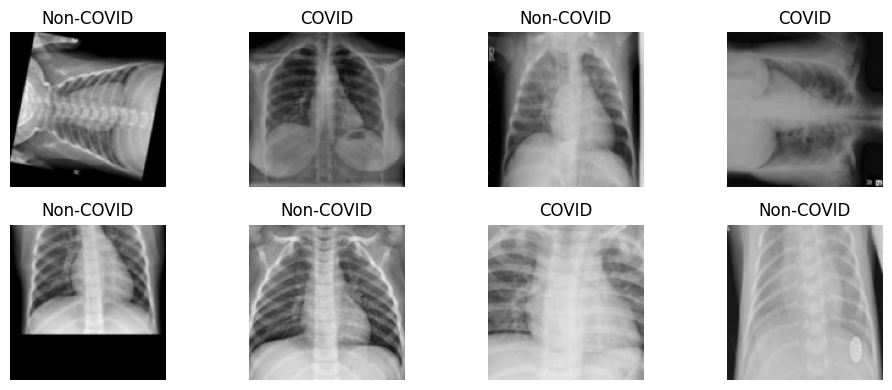

In [5]:
# Grab one batch
images, labels = next(iter(train_loader))
class_names = train_ds.classes

plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    # tensor shape is [C, H, W]; matplotlib wants [H, W, C]
    plt.imshow(images[i].permute(1, 2, 0))
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Build the CNN — and understand its parts



In [6]:
class SimpleCNN(nn.Module):
    def __init__(self, p_dropout=0.0):
        super().__init__()
        # Feature extractor: 3 convolution layers
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool  = nn.MaxPool2d(2, 2)

        # Classification head
        self.dropout = nn.Dropout(p_dropout)
        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Build the model (no dropout for Round 1) and print it
model = SimpleCNN(p_dropout=0.0).to(device)
print(model)

n_params = sum(p.numel() for p in model.parameters())
print(f"\nTotal trainable parameters: {n_params:,}")

SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.0, inplace=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)

Total trainable parameters: 2,121,122


## 5. Train the model (Round 1 — no augmentation)



In [7]:
def train_model(model, train_loader, val_loader, epochs=15, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # We record these each epoch so we can plot curves afterwards
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        # TRAINING
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * imgs.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss = running_loss / total
        train_acc = correct / total

        #  VALIDATION
        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                running_loss += loss.item() * imgs.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
        val_loss = running_loss / total
        val_acc = correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1:2d}/{epochs}  "
              f"train_loss={train_loss:.3f} train_acc={train_acc:.3f}  |  "
              f"val_loss={val_loss:.3f} val_acc={val_acc:.3f}")

    return history

# Train Round 1
history_plain = train_model(model, train_loader, val_loader, epochs=15)

Epoch  1/15  train_loss=0.411 train_acc=0.799  |  val_loss=0.701 val_acc=0.602
Epoch  2/15  train_loss=0.298 train_acc=0.881  |  val_loss=0.943 val_acc=0.608
Epoch  3/15  train_loss=0.244 train_acc=0.905  |  val_loss=0.698 val_acc=0.668
Epoch  4/15  train_loss=0.224 train_acc=0.912  |  val_loss=0.601 val_acc=0.733
Epoch  5/15  train_loss=0.181 train_acc=0.932  |  val_loss=0.638 val_acc=0.744
Epoch  6/15  train_loss=0.154 train_acc=0.945  |  val_loss=0.844 val_acc=0.685
Epoch  7/15  train_loss=0.133 train_acc=0.951  |  val_loss=0.560 val_acc=0.775
Epoch  8/15  train_loss=0.116 train_acc=0.959  |  val_loss=0.727 val_acc=0.711
Epoch  9/15  train_loss=0.103 train_acc=0.963  |  val_loss=0.687 val_acc=0.778
Epoch 10/15  train_loss=0.083 train_acc=0.970  |  val_loss=0.658 val_acc=0.752
Epoch 11/15  train_loss=0.074 train_acc=0.973  |  val_loss=1.085 val_acc=0.698
Epoch 12/15  train_loss=0.064 train_acc=0.976  |  val_loss=1.410 val_acc=0.670
Epoch 13/15  train_loss=0.059 train_acc=0.977  |  va

### Plot the loss and accuracy curves

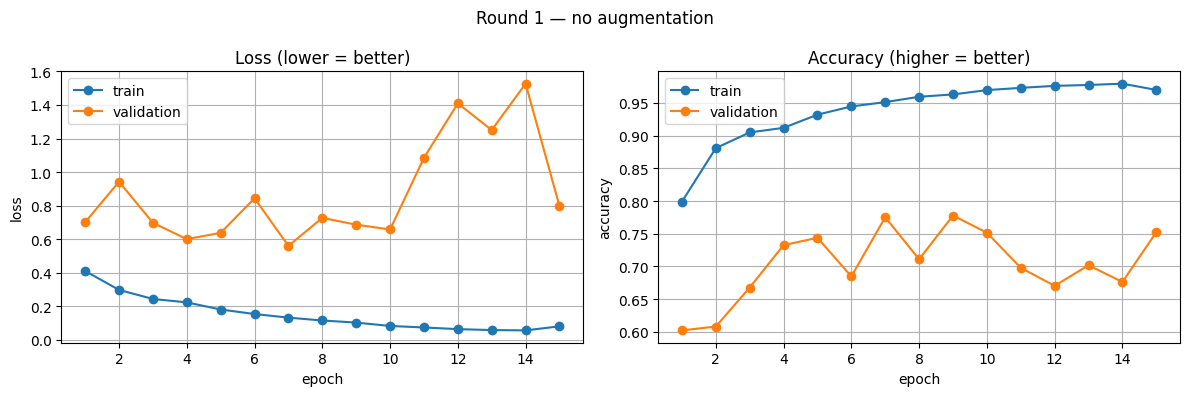

In [8]:
def plot_history(history, title=""):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(epochs, history["train_loss"], "o-", label="train")
    ax1.plot(epochs, history["val_loss"],   "o-", label="validation")
    ax1.set_title("Loss (lower = better)")
    ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.legend(); ax1.grid(True)

    ax2.plot(epochs, history["train_acc"], "o-", label="train")
    ax2.plot(epochs, history["val_acc"],   "o-", label="validation")
    ax2.set_title("Accuracy (higher = better)")
    ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.legend(); ax2.grid(True)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history_plain, "Round 1 — no augmentation")

## 6. Spot the overfitting

- **Training accuracy** goes up to about 97%, and training loss keeps dropping.
- **Validation accuracy** stays low and unstable (about 60%-78%), and validation loss does not go down.

This big gap between train and validation is **overfitting**: the model memorizes the 9,537 training images and does worse on new images. The confusion matrix shows many Non-COVID images predicted as COVID (only 414 of 763 correct). Validation accuracy at the end is about 75.2%.

## 7. Visualize the filters



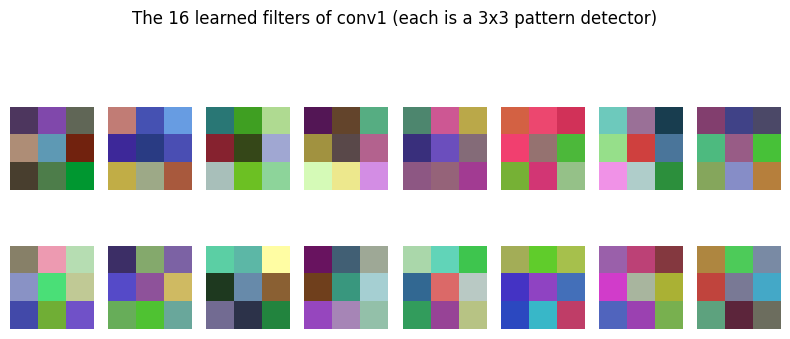

In [9]:
# (1) Show the 16 filters of the first conv layer
weights = model.conv1.weight.data.clone().cpu()

# Scale weights to [0,1] so we can display them as small colour images
w_min, w_max = weights.min(), weights.max()
weights = (weights - w_min) / (w_max - w_min + 1e-8)

plt.figure(figsize=(8, 4))
for i in range(16):
    plt.subplot(2, 8, i + 1)
    plt.imshow(weights[i].permute(1, 2, 0))
    plt.axis("off")
plt.suptitle("The 16 learned filters of conv1 (each is a 3x3 pattern detector)")
plt.tight_layout()
plt.show()

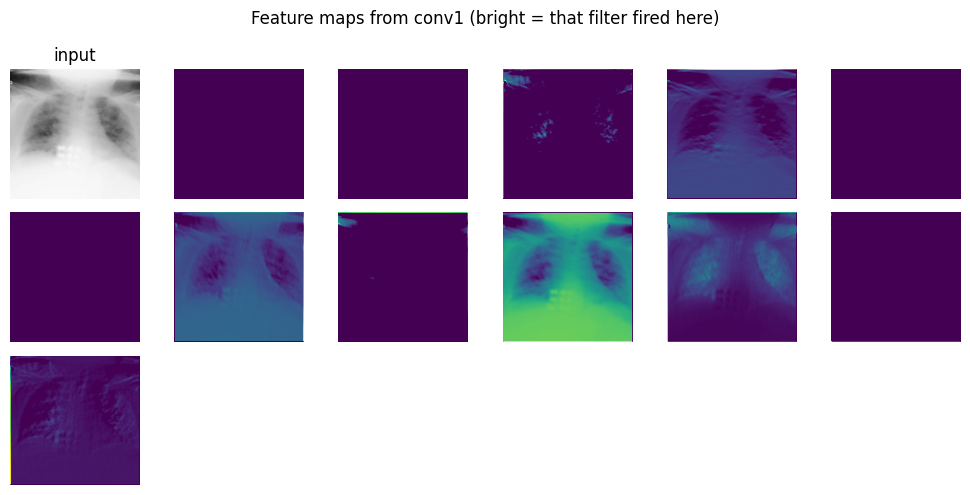

In [10]:
# (2) Show feature maps: how conv1 responds to one real image
img, label = val_ds[0]
img_batch = img.unsqueeze(0).to(device)
model.eval()
with torch.no_grad():
    feature_maps = F.relu(model.conv1(img_batch)).cpu()[0]

plt.figure(figsize=(10, 5))
# original image
plt.subplot(3, 6, 1)
plt.imshow(img.permute(1, 2, 0)); plt.title("input"); plt.axis("off")
# first 12 feature maps
for i in range(12):
    plt.subplot(3, 6, i + 2)
    plt.imshow(feature_maps[i], cmap="viridis")
    plt.axis("off")
plt.suptitle("Feature maps from conv1 (bright = that filter fired here)")
plt.tight_layout()
plt.show()

Last conv layer (conv3) output shape: (64, 32, 32)


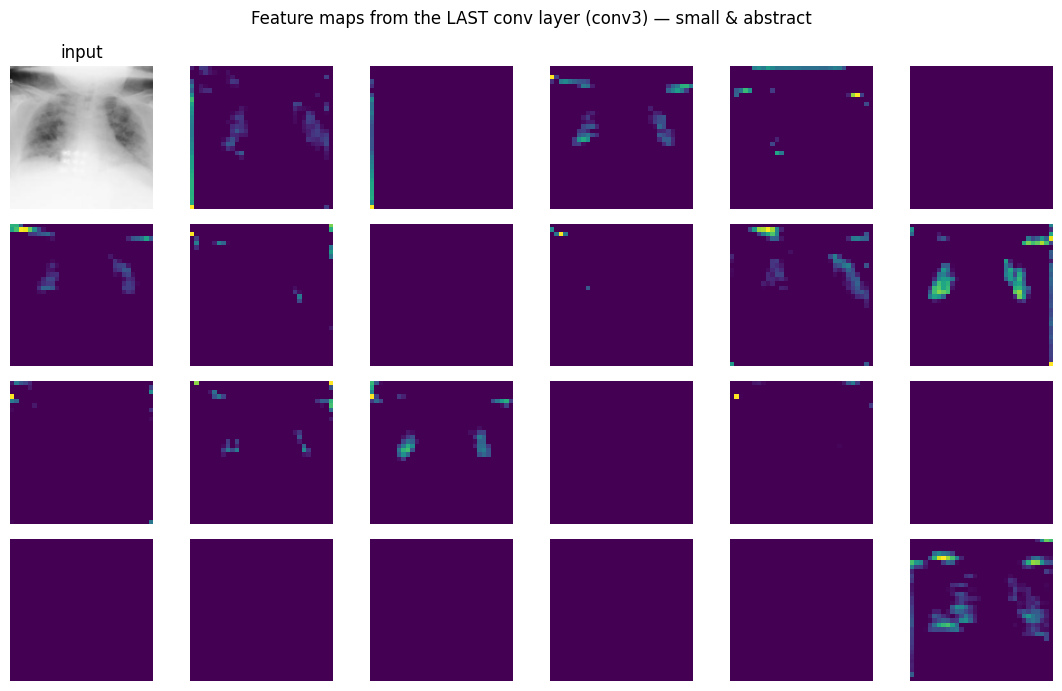

In [11]:
model.eval()
img, _ = val_ds[0]
x = img.unsqueeze(0).to(device)

with torch.no_grad():
    x = model.pool(F.relu(model.conv1(x)))
    x = model.pool(F.relu(model.conv2(x)))
    last_maps = F.relu(model.conv3(x)).cpu()[0]

print("Last conv layer (conv3) output shape:", tuple(last_maps.shape))

plt.figure(figsize=(11, 7))
plt.subplot(4, 6, 1)
plt.imshow(img.permute(1, 2, 0)); plt.title("input"); plt.axis("off")
for i in range(23):
    plt.subplot(4, 6, i + 2)
    plt.imshow(last_maps[i], cmap="viridis")
    plt.axis("off")
plt.suptitle("Feature maps from the LAST conv layer (conv3) — small & abstract")
plt.tight_layout()
plt.show()

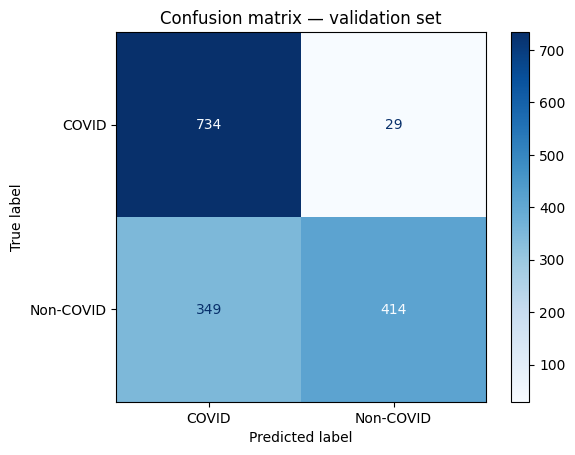

              precision    recall  f1-score   support

       COVID       0.68      0.96      0.80       763
   Non-COVID       0.93      0.54      0.69       763

    accuracy                           0.75      1526
   macro avg       0.81      0.75      0.74      1526
weighted avg       0.81      0.75      0.74      1526



In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

def get_predictions(model, loader):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            outputs = model(imgs.to(device))
            preds.append(outputs.argmax(1).cpu())
            targets.append(labels)
    return torch.cat(preds).numpy(), torch.cat(targets).numpy()

# Choose which model + validation loader to evaluate
# Round 2 model on the clean validation set:
y_pred, y_true = get_predictions(model, val_loader)
class_names = val_ds.classes

# (For Round 1 instead, use: get_predictions(model, val_loader) and class_names = val_ds.classes)

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix — validation set")
plt.show()

# Per-class precision, recall, f1
print(classification_report(y_true, y_pred, target_names=class_names))

## 8. Fix the overfitting — Round 2: **with transforms (augmentation) + dropout**



In [13]:
# Training transform WITH augmentation
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
])

# Validation transform stays basic (no augmentation!)
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

train_ds_aug = datasets.ImageFolder(train_dir, transform=train_transform)
val_ds_clean = datasets.ImageFolder(val_dir,   transform=val_transform)

train_loader_aug = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader_clean = DataLoader(val_ds_clean, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Augmented training pipeline ready.")

Augmented training pipeline ready.


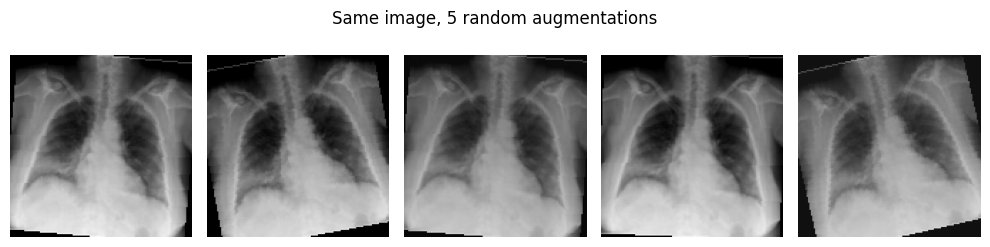

In [14]:
# See the SAME image augmented differently each time
sample_img, _ = train_ds_aug[0]
plt.figure(figsize=(10, 2.5))
for i in range(5):
    aug_img, _ = train_ds_aug[0]     # re-fetching re-applies random transforms
    plt.subplot(1, 5, i + 1)
    plt.imshow(aug_img.permute(1, 2, 0))
    plt.axis("off")
plt.suptitle("Same image, 5 random augmentations")
plt.tight_layout()
plt.show()

Epoch  1/20  train_loss=0.453 train_acc=0.781  |  val_loss=0.837 val_acc=0.566
Epoch  2/20  train_loss=0.353 train_acc=0.848  |  val_loss=0.600 val_acc=0.683
Epoch  3/20  train_loss=0.321 train_acc=0.858  |  val_loss=0.699 val_acc=0.589
Epoch  4/20  train_loss=0.296 train_acc=0.878  |  val_loss=0.763 val_acc=0.604
Epoch  5/20  train_loss=0.271 train_acc=0.892  |  val_loss=0.800 val_acc=0.637
Epoch  6/20  train_loss=0.256 train_acc=0.897  |  val_loss=0.575 val_acc=0.723
Epoch  7/20  train_loss=0.242 train_acc=0.907  |  val_loss=0.834 val_acc=0.626
Epoch  8/20  train_loss=0.235 train_acc=0.908  |  val_loss=0.663 val_acc=0.691
Epoch  9/20  train_loss=0.213 train_acc=0.915  |  val_loss=0.861 val_acc=0.645
Epoch 10/20  train_loss=0.202 train_acc=0.923  |  val_loss=0.654 val_acc=0.703
Epoch 11/20  train_loss=0.200 train_acc=0.925  |  val_loss=0.819 val_acc=0.682
Epoch 12/20  train_loss=0.185 train_acc=0.928  |  val_loss=0.596 val_acc=0.753
Epoch 13/20  train_loss=0.186 train_acc=0.930  |  va

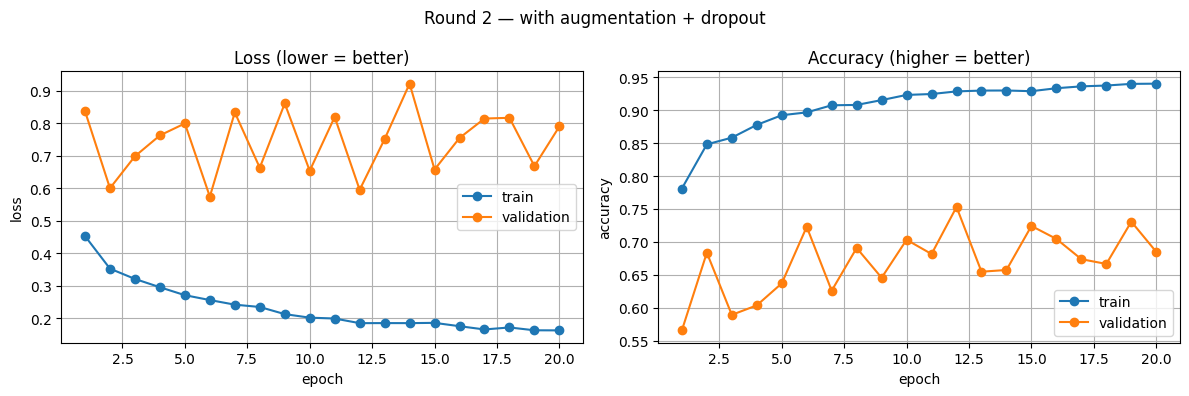

In [15]:
# Fresh model, now WITH dropout, trained on augmented data
model_aug = SimpleCNN(p_dropout=0.5).to(device)

history_aug = train_model(model_aug, train_loader_aug, val_loader_clean, epochs=20)
plot_history(history_aug, "Round 2 — with augmentation + dropout")


## 9. Compare the two rounds

Best validation accuracy: Round 1 = 77.8%, Round 2 = 75.3%. At the end, Round 2 has lower training accuracy (about 94%) but validation accuracy is still unstable (68.5%). So augmentation and dropout did not fix the overfitting here. The model still predicts many Non-COVID images as COVID (only 297 of 763 correct).

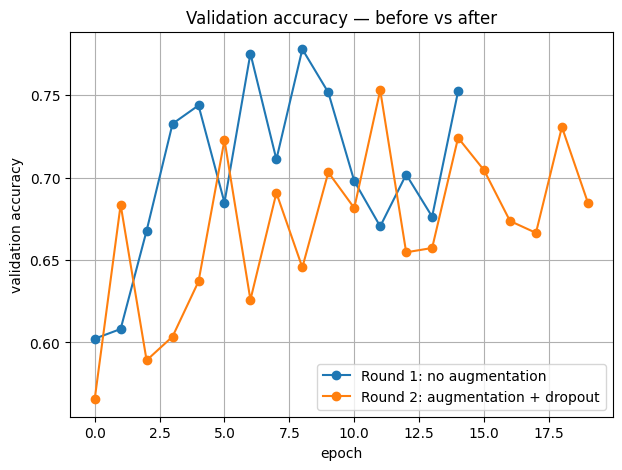

Best val acc  (Round 1): 0.778
Best val acc  (Round 2): 0.753


In [16]:
plt.figure(figsize=(7, 5))
plt.plot(history_plain["val_acc"], "o-", label="Round 1: no augmentation")
plt.plot(history_aug["val_acc"],   "o-", label="Round 2: augmentation + dropout")
plt.title("Validation accuracy — before vs after")
plt.xlabel("epoch"); plt.ylabel("validation accuracy")
plt.legend(); plt.grid(True)
plt.show()

print(f"Best val acc  (Round 1): {max(history_plain['val_acc']):.3f}")
print(f"Best val acc  (Round 2): {max(history_aug['val_acc']):.3f}")

Last conv layer (conv3) output shape: (64, 32, 32)


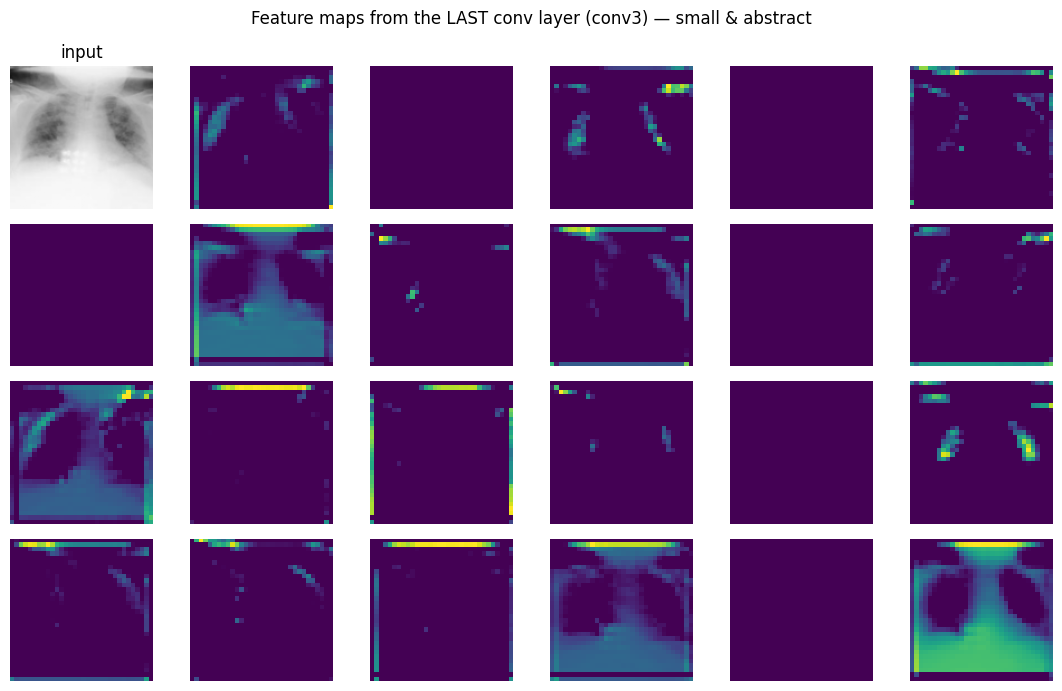

In [17]:
model_aug.eval()
img, _ = val_ds[0]
x = img.unsqueeze(0).to(device)

with torch.no_grad():
    x = model_aug.pool(F.relu(model_aug.conv1(x)))
    x = model_aug.pool(F.relu(model_aug.conv2(x)))
    last_maps = F.relu(model_aug.conv3(x)).cpu()[0]

print("Last conv layer (conv3) output shape:", tuple(last_maps.shape))

plt.figure(figsize=(11, 7))
plt.subplot(4, 6, 1)
plt.imshow(img.permute(1, 2, 0)); plt.title("input"); plt.axis("off")
for i in range(23):
    plt.subplot(4, 6, i + 2)
    plt.imshow(last_maps[i], cmap="viridis")
    plt.axis("off")
plt.suptitle("Feature maps from the LAST conv layer (conv3) — small & abstract")
plt.tight_layout()
plt.show()

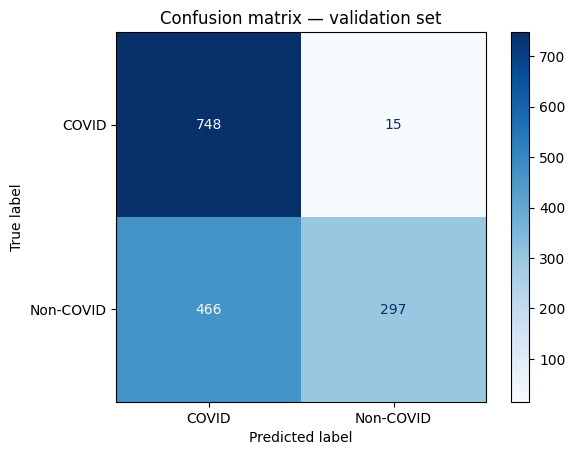

              precision    recall  f1-score   support

       COVID       0.62      0.98      0.76       763
   Non-COVID       0.95      0.39      0.55       763

    accuracy                           0.68      1526
   macro avg       0.78      0.68      0.65      1526
weighted avg       0.78      0.68      0.65      1526



In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

def get_predictions(model, loader):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            outputs = model(imgs.to(device))
            preds.append(outputs.argmax(1).cpu())
            targets.append(labels)
    return torch.cat(preds).numpy(), torch.cat(targets).numpy()

# Round 2 model on the clean validation set:
y_pred, y_true = get_predictions(model_aug, val_loader_clean)
class_names = val_ds_clean.classes

# (For Round 1 instead, use: get_predictions(model, val_loader) and class_names = val_ds.classes)

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix — validation set")
plt.show()

# Per-class precision, recall, f1
print(classification_report(y_true, y_pred, target_names=class_names))


## 10. Recap

The CNN overfits: training accuracy is high (94-97%) but validation accuracy is only about 68-78%. Augmentation and dropout did not improve validation accuracy. The model confuses Non-COVID images as COVID.